# Data Profiling & Quality Risk Analysis
## Workshop-2: Building a Reliable Batch Data Pipeline
**Course:** ETL (G01) - Universidad Autónoma de Occidente  
**Scope:** Forensic analysis of Spotify Catalog (CSV) and Grammy Awards (MySQL `grammy_source`) across the **7 mandatory evidence categories** (PDF Section 6.3).

This notebook executes live against the local datasets and operational MySQL database, generating empirical proof for all downstream quality rules, transformation decisions, and dimensional structures.

In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

load_dotenv()

# Setup plot styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

MYSQL_HOST = os.getenv("MYSQL_HOST", "localhost")
MYSQL_PORT = int(os.getenv("MYSQL_PORT", 3306))
MYSQL_USER = os.getenv("MYSQL_USER", "root")
MYSQL_PASSWORD = os.getenv("MYSQL_PASSWORD", "1234")
SOURCE_DB = os.getenv("GRAMMY_SOURCE_DB", "grammy_source")

db_url = f"mysql+pymysql://{MYSQL_USER}:{MYSQL_PASSWORD}@{MYSQL_HOST}:{MYSQL_PORT}/{SOURCE_DB}?charset=utf8mb4"
engine = create_engine(db_url)

print("Libraries imported and MySQL connection configured.")


Libraries imported and MySQL connection configured.


In [2]:
# Load Spotify Dataset from CSV
from pathlib import Path
BASE_DIR = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
spotify_path = BASE_DIR / "data" / "spotify_dataset.csv"
evidence_dir = BASE_DIR / "docs" / "evidence"
evidence_dir.mkdir(parents=True, exist_ok=True)

df_spotify = pd.read_csv(spotify_path)

# Load Grammy Dataset from MySQL Source Table (Strict Architectural Rule)
with engine.connect() as conn:
    df_grammy = pd.read_sql("SELECT * FROM grammy_awards_raw", conn)

print(f"Spotify Raw Dimensions: {df_spotify.shape[0]:,} rows, {df_spotify.shape[1]} columns")
print(f"Grammy MySQL Dimensions: {df_grammy.shape[0]:,} rows, {df_grammy.shape[1]} columns")


Spotify Raw Dimensions: 114,000 rows, 21 columns
Grammy MySQL Dimensions: 4,810 rows, 12 columns


### Evidence Category 1: Structure
Evaluation of schemas, columns, data types, and availability of required fields for **REQ-01**, **REQ-02**, and **REQ-03**.

In [3]:
print("--- SPOTIFY CATALOG STRUCTURE ---")
spotify_struct = pd.DataFrame({
    'Column': df_spotify.columns,
    'Dtype': df_spotify.dtypes.values,
    'Sample': [str(df_spotify[c].iloc[0])[:30] for c in df_spotify.columns]
})
print(spotify_struct.to_string(index=False))

print("\n--- GRAMMY AWARDS (MySQL) STRUCTURE ---")
grammy_struct = pd.DataFrame({
    'Column': df_grammy.columns,
    'Dtype': df_grammy.dtypes.values,
    'Sample': [str(df_grammy[c].iloc[0])[:30] for c in df_grammy.columns]
})
print(grammy_struct.to_string(index=False))


--- SPOTIFY CATALOG STRUCTURE ---
          Column   Dtype                 Sample
      Unnamed: 0   int64                      0
        track_id     str 5SuOikwiRyPMVoIQDJUgSV
         artists     str            Gen Hoshino
      album_name     str                 Comedy
      track_name     str                 Comedy
      popularity   int64                     73
     duration_ms   int64                 230666
        explicit    bool                  False
    danceability float64                  0.676
          energy float64                  0.461
             key   int64                      1
        loudness float64                 -6.746
            mode   int64                      0
     speechiness float64                  0.143
    acousticness float64                 0.0322
instrumentalness float64               1.01e-06
        liveness float64                  0.358
         valence float64                  0.715
           tempo float64                 87.917
  time

### Evidence Category 2: Completeness
Evaluation of missing values, null counts, and business context interpretation.

Spotify Attributes with Missing Values:
  artists: 1 missing (0.0009%)
  album_name: 1 missing (0.0009%)
  track_name: 1 missing (0.0009%)

Grammy Attributes with Missing Values:
  nominee: 6 missing (0.12%)
  artist: 1,840 missing (38.25%)
  workers: 2,190 missing (45.53%)
  img: 1,367 missing (28.42%)


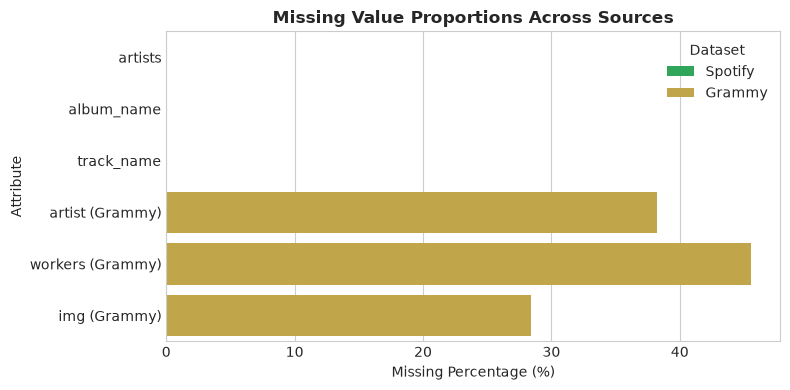

Saved chart: C:\Users\mauri\OneDrive\Escritorio\etl\workshop prueba\docs\evidence\profiling_missing_values.png


In [4]:
# Completeness Analysis
sp_nulls = df_spotify.isnull().sum()
sp_nulls = sp_nulls[sp_nulls > 0]
print("Spotify Attributes with Missing Values:")
for col, val in sp_nulls.items():
    print(f"  {col}: {val} missing ({val/len(df_spotify):.4%})")

gr_nulls = df_grammy.isnull().sum()
gr_nulls = gr_nulls[gr_nulls > 0]
print("\nGrammy Attributes with Missing Values:")
for col, val in gr_nulls.items():
    print(f"  {col}: {val:,} missing ({val/len(df_grammy):.2%})")

# Visual chart for missing values
fig, ax = plt.subplots(figsize=(8, 4))
null_df = pd.DataFrame({
    'Attribute': ['artists', 'album_name', 'track_name', 'artist (Grammy)', 'workers (Grammy)', 'img (Grammy)'],
    'Missing_Pct': [1/114000*100, 1/114000*100, 1/114000*100, 1840/4810*100, 2190/4810*100, 1367/4810*100],
    'Dataset': ['Spotify', 'Spotify', 'Spotify', 'Grammy', 'Grammy', 'Grammy']
})
sns.barplot(data=null_df, x='Missing_Pct', y='Attribute', hue='Dataset', palette=['#1DB954', '#D4AF37'], ax=ax)
ax.set_title("Missing Value Proportions Across Sources", fontsize=12, fontweight='bold')
ax.set_xlabel("Missing Percentage (%)")
plt.tight_layout()
fig.savefig(evidence_dir / "profiling_missing_values.png", dpi=150)
plt.show()
print(f"Saved chart: {evidence_dir / 'profiling_missing_values.png'}")


### Evidence Category 3: Uniqueness and Duplication
Investigation of candidate keys, duplicate patterns, and empirical proof of multi-genre track assignment.

In [5]:
print(f"Total rows in Spotify: {len(df_spotify):,}")
print(f"Distinct track_id values: {df_spotify['track_id'].nunique():,}")
print(f"Rows with repeated track_id: {df_spotify.duplicated(subset=['track_id']).sum():,}")

# Exact technical duplicates across all attributes (excluding Unnamed: 0)
spotify_no_idx = df_spotify.drop(columns=['Unnamed: 0'])
exact_duplicates = spotify_no_idx.duplicated().sum()
print(f"Exact duplicate rows across all content columns: {exact_duplicates}")

# Composite candidate key (track_id, track_genre)
genre_duplicates = df_spotify.duplicated(subset=['track_id', 'track_genre']).sum()
print(f"Duplicate (track_id, track_genre) pairs: {genre_duplicates}")

# Rows with missing core identity (artists is null)
null_identity = df_spotify['artists'].isnull().sum()
print(f"Rows with null artists: {null_identity}")

valid_analytical_observations = len(df_spotify) - genre_duplicates - null_identity
print(f"Target analytical dataset size: {valid_analytical_observations:,} (114,000 - 451 non-analytical rows = 113,549)")


Total rows in Spotify: 114,000
Distinct track_id values: 89,741
Rows with repeated track_id: 24,259
Exact duplicate rows across all content columns: 450


Duplicate (track_id, track_genre) pairs: 450
Rows with null artists: 1
Target analytical dataset size: 113,549 (114,000 - 451 non-analytical rows = 113,549)


### Evidence Category 4: Categorical Content
Analysis of categorical domains, genres, multi-artist strings, and nomination categories.

In [6]:
print(f"Distinct genres in Spotify: {df_spotify['track_genre'].nunique()}")
print(f"Tracks per genre (top 5):\n{df_spotify['track_genre'].value_counts().head(5)}")

# Semicolon analysis in artists
multi_artist_count = df_spotify['artists'].dropna().str.contains(';').sum()
print(f"\nTracks with multiple artists (semicolon-delimited): {multi_artist_count:,} ({multi_artist_count/len(df_spotify):.2%})")

# Grammy Categories
print(f"\nDistinct award categories in Grammy Awards: {df_grammy['category'].nunique()}")
print(f"Top 5 Grammy categories by award count:\n{df_grammy['category'].value_counts().head(5)}")


Distinct genres in Spotify: 114
Tracks per genre (top 5):
track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
Name: count, dtype: int64

Tracks with multiple artists (semicolon-delimited): 30,075 (26.38%)

Distinct award categories in Grammy Awards: 638
Top 5 Grammy categories by award count:
category
Song Of The Year        70
Record Of The Year      69
Album Of The Year       66
Best Opera Recording    64
Best Album Notes        63
Name: count, dtype: int64


### Evidence Category 5: Numerical Content & Quantiles
Evaluation of numerical distributions, bounds, and empirical quantiles for Spotify popularity ($P_{25}, P_{50}, P_{75}$).

--- SPOTIFY POPULARITY DISTRIBUTION ---
Min: 0, Max: 100, Mean: 33.24, Std: 22.31
25th Percentile (P25): 17.0
50th Percentile (P50 - Median): 35.0
75th Percentile (P75): 50.0
-> EMPIRICAL PROOF: P75 is exactly 50.0 points. This provides the mathematical basis for REQ-03 High Popularity Share.


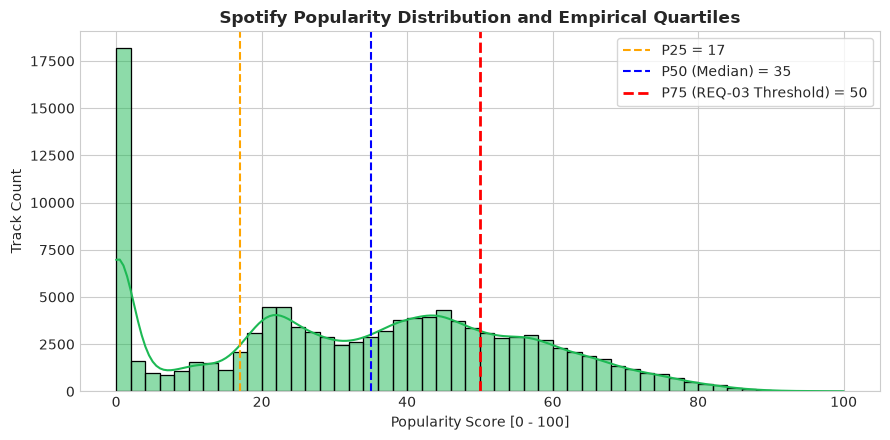

Saved chart: C:\Users\mauri\OneDrive\Escritorio\etl\workshop prueba\docs\evidence\profiling_popularity_distribution.png


In [7]:
# Popularity statistics
pop = df_spotify['popularity']
q25 = pop.quantile(0.25)
q50 = pop.quantile(0.50)
q75 = pop.quantile(0.75)

print("--- SPOTIFY POPULARITY DISTRIBUTION ---")
print(f"Min: {pop.min()}, Max: {pop.max()}, Mean: {pop.mean():.2f}, Std: {pop.std():.2f}")
print(f"25th Percentile (P25): {q25:.1f}")
print(f"50th Percentile (P50 - Median): {q50:.1f}")
print(f"75th Percentile (P75): {q75:.1f}")
print("-> EMPIRICAL PROOF: P75 is exactly 50.0 points. This provides the mathematical basis for REQ-03 High Popularity Share.")

# Plot Popularity Distribution
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(pop, bins=50, kde=True, color='#1DB954', ax=ax)
ax.axvline(q25, color='orange', linestyle='--', label=f'P25 = {q25:.0f}')
ax.axvline(q50, color='blue', linestyle='--', label=f'P50 (Median) = {q50:.0f}')
ax.axvline(q75, color='red', linestyle='--', linewidth=2, label=f'P75 (REQ-03 Threshold) = {q75:.0f}')
ax.set_title("Spotify Popularity Distribution and Empirical Quartiles", fontsize=12, fontweight='bold')
ax.set_xlabel("Popularity Score [0 - 100]")
ax.set_ylabel("Track Count")
ax.legend(frameon=True)
plt.tight_layout()
fig.savefig(evidence_dir / "profiling_popularity_distribution.png", dpi=150)
plt.show()
print(f"Saved chart: {evidence_dir / 'profiling_popularity_distribution.png'}")


--- AUDIO FEATURES BOUNDS & SUMMARY ---
                     min        mean      max
danceability       0.000    0.566800    0.985
energy             0.000    0.641383    1.000
loudness         -49.531   -8.258960    4.532
speechiness        0.000    0.084652    0.965
acousticness       0.000    0.314910    0.996
instrumentalness   0.000    0.156050    1.000
liveness           0.000    0.213553    1.000
valence            0.000    0.474068    0.995
tempo              0.000  122.147837  243.372


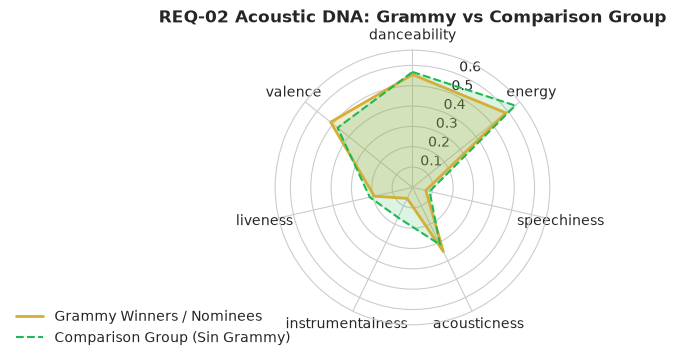

Saved chart: C:\Users\mauri\OneDrive\Escritorio\etl\workshop prueba\docs\evidence\profiling_audio_features_radar.png


In [8]:
# 9 Audio Dimensions Analysis for REQ-02
audio_cols = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
print("--- AUDIO FEATURES BOUNDS & SUMMARY ---")
print(df_spotify[audio_cols].describe().T[['min', 'mean', 'max']].to_string())

# Create a normalized radar chart comparison for Grammy artists vs Control Group
# Extract cleaned artist list from Grammy
gr_artists = set(df_grammy['artist'].dropna().str.strip().str.lower().unique())
df_spotify['primary_artist_norm'] = df_spotify['artists'].astype(str).str.split(';').str[0].str.strip().str.lower()
df_spotify['has_grammy'] = df_spotify['primary_artist_norm'].isin(gr_artists).astype(int)

# Normalize features to [0, 1] for radar chart
features_to_radar = ['danceability', 'energy', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence']
means_grammy = df_spotify[df_spotify['has_grammy'] == 1][features_to_radar].mean().tolist()
means_control = df_spotify[df_spotify['has_grammy'] == 0][features_to_radar].mean().tolist()

labels = features_to_radar
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
means_grammy += means_grammy[:1]
means_control += means_control[:1]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
ax.plot(angles, means_grammy, color='#D4AF37', linewidth=2, label='Grammy Winners / Nominees')
ax.fill(angles, means_grammy, color='#D4AF37', alpha=0.25)
ax.plot(angles, means_control, color='#1DB954', linewidth=1.5, linestyle='--', label='Comparison Group (Sin Grammy)')
ax.fill(angles, means_control, color='#1DB954', alpha=0.15)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), labels)
ax.set_title("REQ-02 Acoustic DNA: Grammy vs Comparison Group", fontsize=12, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.tight_layout()
fig.savefig(evidence_dir / "profiling_audio_features_radar.png", dpi=150)
plt.show()
print(f"Saved chart: {evidence_dir / 'profiling_audio_features_radar.png'}")


### Evidence Category 6: Temporal Content
Analysis of temporal ranges, decade derivations (`1960s` to `2010s`), and award distribution over time.

Grammy Year Range: 1958 to 2019


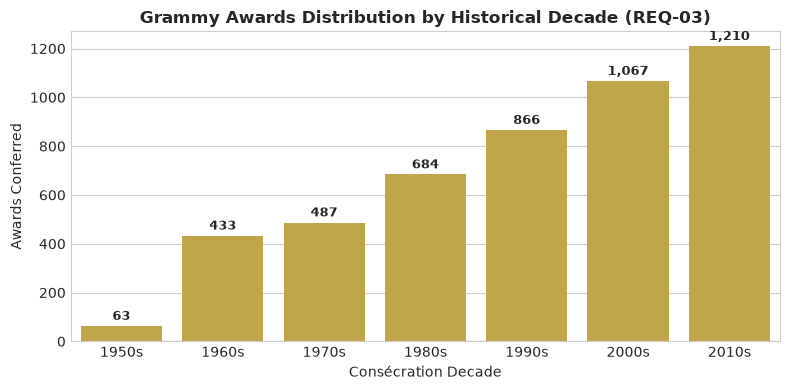

Saved chart: C:\Users\mauri\OneDrive\Escritorio\etl\workshop prueba\docs\evidence\profiling_grammy_decades.png


In [9]:
print(f"Grammy Year Range: {df_grammy['year'].min()} to {df_grammy['year'].max()}")

# Derive Decades
df_grammy['decade'] = (df_grammy['year'] // 10 * 10).astype(str) + "s"
decade_counts = df_grammy['decade'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=decade_counts.index, y=decade_counts.values, color='#D4AF37', ax=ax)
ax.set_title("Grammy Awards Distribution by Historical Decade (REQ-03)", fontsize=12, fontweight='bold')
ax.set_xlabel("Consécration Decade")
ax.set_ylabel("Awards Conferred")
for i, v in enumerate(decade_counts.values):
    ax.text(i, v + 25, f"{v:,}", ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
fig.savefig(evidence_dir / "profiling_grammy_decades.png", dpi=150)
plt.show()
print(f"Saved chart: {evidence_dir / 'profiling_grammy_decades.png'}")


### Evidence Category 7 & Quality Risk Analysis
Cross-source compatibility, artist integration challenges, and the formal Quality Risk Matrix.

In [10]:
# Matching analysis
spotify_unique_artists = set(df_spotify['primary_artist_norm'].unique())
overlap = spotify_unique_artists.intersection(gr_artists)
print(f"Distinct Spotify primary artists: {len(spotify_unique_artists):,}")
print(f"Distinct Grammy artists: {len(gr_artists):,}")
print(f"Overlapping artists: {len(overlap):,}")

# Official Quality Risk Register
risk_data = [
    {
        "Dataset / Attribute": "Spotify: track_id, track_genre",
        "Profiling Evidence": "450 exact duplicate rows across all content attributes; track_id repeats legally across genres.",
        "Potential Quality Risk": "Distorted aggregation counts and duplicate fact records in DW.",
        "Related Requirement": "REQ-01, REQ-02, REQ-03"
    },
    {
        "Dataset / Attribute": "Spotify: popularity",
        "Profiling Evidence": "Empirical range [0, 100], P75 exactly 50.0. 15,843 zero-popularity records.",
        "Potential Quality Risk": "Out-of-range values (>100 or <0) corrupt lift calculations and P75 metric.",
        "Related Requirement": "REQ-01, REQ-03"
    },
    {
        "Dataset / Attribute": "Spotify: artists, track_name",
        "Profiling Evidence": "1 row (index 65900) has null artists, album_name, and track_name.",
        "Potential Quality Risk": "Null foreign keys in star schema; broken artist integration.",
        "Related Requirement": "REQ-01, REQ-02, REQ-03"
    },
    {
        "Dataset / Attribute": "Spotify: 9 Audio Features",
        "Profiling Evidence": "danceability, energy, speechiness, etc., strictly bounded in [0.0, 1.0]; loudness in [-60, 0].",
        "Potential Quality Risk": "Abnormal acoustical readings distort acoustic DNA radar profiling.",
        "Related Requirement": "REQ-02"
    },
    {
        "Dataset / Attribute": "Grammy: artist, category",
        "Profiling Evidence": "1,840 records with null artist; Best New Artist stores artist in nominee.",
        "Potential Quality Risk": "Omission of recognized artists during cross-source matching.",
        "Related Requirement": "REQ-01, REQ-02, REQ-03"
    },
    {
        "Dataset / Attribute": "Grammy: year",
        "Profiling Evidence": "Range 1958 to 2019; all values parseable integers.",
        "Potential Quality Risk": "Invalid or missing years would invalidate decade cohort derivation.",
        "Related Requirement": "REQ-03"
    },
    {
        "Dataset / Attribute": "Integration: artists matching",
        "Profiling Evidence": "Case differences, leading/trailing spaces, and multi-artist semicolon lists.",
        "Potential Quality Risk": "False negatives in Grammy recognition matching.",
        "Related Requirement": "REQ-01, REQ-02, REQ-03"
    }
]

df_risks = pd.DataFrame(risk_data)
print("\n=== OFFICIAL QUALITY RISK REGISTER ===")
print(df_risks.to_string(index=False))

# Save summary to evidence
df_risks.to_json(evidence_dir / "quality_risk_register.json", orient="records", indent=4)
print(f"\nAudit evidence saved: {evidence_dir / 'quality_risk_register.json'}")


Distinct Spotify primary artists: 17,640
Distinct Grammy artists: 1,656
Overlapping artists: 438

=== OFFICIAL QUALITY RISK REGISTER ===
           Dataset / Attribute                                                                              Profiling Evidence                                                     Potential Quality Risk    Related Requirement
Spotify: track_id, track_genre 450 exact duplicate rows across all content attributes; track_id repeats legally across genres.             Distorted aggregation counts and duplicate fact records in DW. REQ-01, REQ-02, REQ-03
           Spotify: popularity                     Empirical range [0, 100], P75 exactly 50.0. 15,843 zero-popularity records. Out-of-range values (>100 or <0) corrupt lift calculations and P75 metric.         REQ-01, REQ-03
  Spotify: artists, track_name                               1 row (index 65900) has null artists, album_name, and track_name.               Null foreign keys in star schema; broken artist